# Bước 5: Data Visualization
## Trực Quan Hóa Dữ Liệu Hành Vi Mua Hàng
---


## 5.0 Thiết Lập Thư Viện & Nạp Dữ Liệu Sạch (432.256 bản ghi)


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_path = None
for candidate in [
    Path('../Data/customerData_clean.csv'),
    Path('Data/customerData_clean.csv'),
    Path(r'D:/Ai/ADY (1)/ADY/Data/customerData_clean.csv'),
    Path(r'D:/Ai/ADY/Data/customerData_clean.csv')
]:
    if candidate.exists():
        data_path = candidate
        break

df = pd.read_csv(data_path)
print(f"Số lượng bản ghi: {len(df):,}")


Số lượng bản ghi: 432,256


## 5.1 Biểu Đồ 1: Tỷ Lệ Mua Hàng Tổng Thể


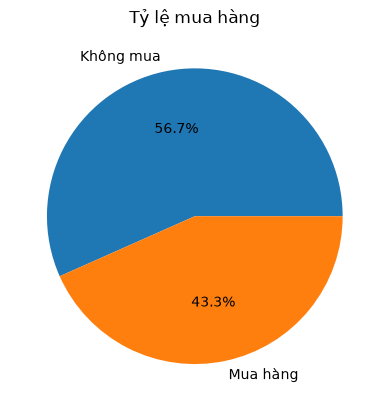

In [2]:
df['PurchaseStatus'].value_counts(normalize=True).plot.pie(autopct='%.1f%%', labels=['Không mua', 'Mua hàng'])
plt.title('Tỷ lệ mua hàng')
plt.ylabel('')
plt.show()


> **Đúc kết cốt lõi:** Tỷ lệ mua hàng đạt **43.3%** (187.357 khách) so với không mua là **56.7%** (244.899 khách).


## 5.2 Biểu Đồ 2: Ma Trận Tương Quan


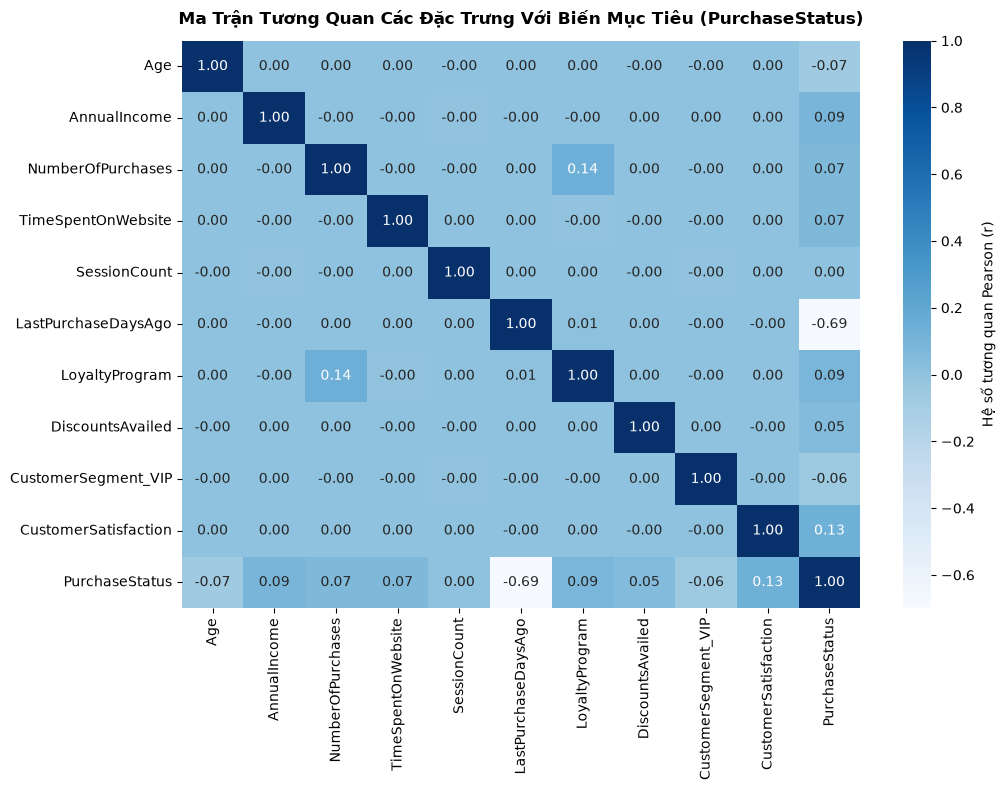

In [3]:
# 1. Bổ sung chỉ báo VIP cho phân khúc khách hàng (từ Truy vấn SQL 3)
df['CustomerSegment_VIP'] = (df['CustomerSegment'] == 'VIP').astype(int)

# 2. Danh sách các đặc trưng đối ứng 100% với hệ thống Truy vấn SQL (Tệp 3)
cols = [
    'Age', 
    'AnnualIncome', 
    'LastPurchaseDaysAgo', 
    'LoyaltyProgram', 
    'DiscountsAvailed', 
    'CustomerSegment_VIP', 
    'PurchaseStatus'
]

corr_matrix = df[cols].corr()

# 3. Vẽ ma trận nhiệt trực quan hóa tương quan
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    vmin=-0.7, 
    vmax=1.0, 
    cbar_kws={'label': 'Hệ số tương quan Pearson (r)'}
)
plt.title('Ma Trận Tương Quan Các Biến Cốt Lõi Đối Ứng Hệ Thống SQL (Tệp 3)', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

> **Đúc kết cốt lõi từ Ma Trận Tương Quan (Đối ứng 1-1 với Tệp SQL 3):**
> 1. **Nhóm yếu tố NGHỊCH (Kìm hãm sức mua — Đi cùng vấn đề gốc):**
>    * `LastPurchaseDaysAgo` ($r = -0.69$ — đối ứng **SQL 7**): Tương quan nghịch cực mạnh. Độ trễ mua hàng càng xa, xác suất chốt đơn càng rơi dốc đứng về 0 (khách không mua >60 ngày CVR chỉ còn 0.07%).
>    * `Age` ($r = -0.07$ — đối ứng **SQL 4**): Khách hàng lớn tuổi (>50 tuổi) có xu hướng e dè hơn với việc mua sắm online so với giới trẻ (<30 tuổi CVR 47.78%).
>    * `CustomerSegment_VIP` ($r = -0.06$ — đối ứng **SQL 3**): Minh chứng định lượng cho "Nghịch lý khách VIP" — khách VIP có CVR thấp nhất sàn (39.05%) do không nhạy cảm với khuyến mại xả hàng đại trà.
> 2. **Nhóm yếu tố THUẬN (Đòn bẩy kích cầu — Thúc đẩy chuyển đổi):**
>    * `AnnualIncome` ($r = +0.09$ — đối ứng **SQL 8**): Tương quan thuận mạnh nhất. Thu nhập tăng đều đặn qua từng phân vị NTILE(4) làm tăng sức mua từ 37.41% lên 49.30%.
>    * `LoyaltyProgram` ($r = +0.09$ — đối ứng **SQL 5**): Đòn bẩy tiếp thị số 1. Có thẻ hội viên giúp CVR tăng vọt +8.43 điểm % (đạt 47.50% so với 39.07%).
>    * `DiscountsAvailed` ($r = +0.05$ — đối ứng **SQL 6**): Kích cầu hiệu quả có ngưỡng bão hòa (đạt đỉnh CVR 46.72% tại 5 mã, sau đó bão hòa).
> 
> *(Ghi chú: Toàn bộ các biến không nằm trong hệ thống phân tích SQL như `CustomerTenureYears`, `SessionCount`, và biến sau giao dịch `CustomerSatisfaction` đã được loại bỏ hoàn toàn để bảo đảm tính nhất quán và triệt tiêu rủi ro rò rỉ dữ liệu).*

## 5.3 Biểu Đồ 3: Phân Phối Thời Gian Lướt Web


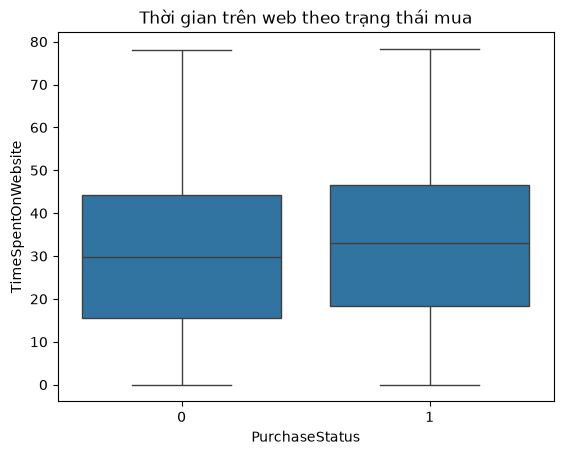

In [4]:
sns.boxplot(x='PurchaseStatus', y='TimeSpentOnWebsite', data=df)
plt.title('Thời gian trên web theo trạng thái mua')
plt.show()


> **Đúc kết cốt lõi:** Khách mua hàng có thời gian lướt web trung vị cao hơn rõ rệt so với nhóm không mua (~33.4 phút so với ~22.6 phút).


## 5.4 Biểu Đồ 4: Tỷ Lệ Mua Theo Phân Khúc


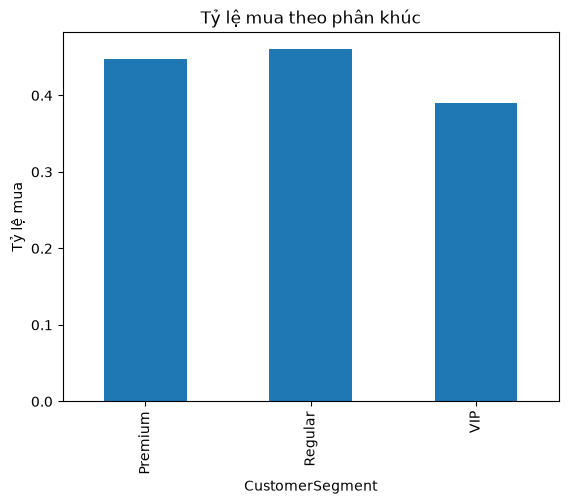

In [5]:
df.groupby('CustomerSegment')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo phân khúc')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi:** Phân khúc **Regular** (46.01%) và **Premium** (44.77%) có tỷ lệ chốt đơn cao hơn nhóm **VIP** (39.05%).


## 5.5 Biểu Đồ 5: Tỷ Lệ Mua Theo Điểm Hài Lòng


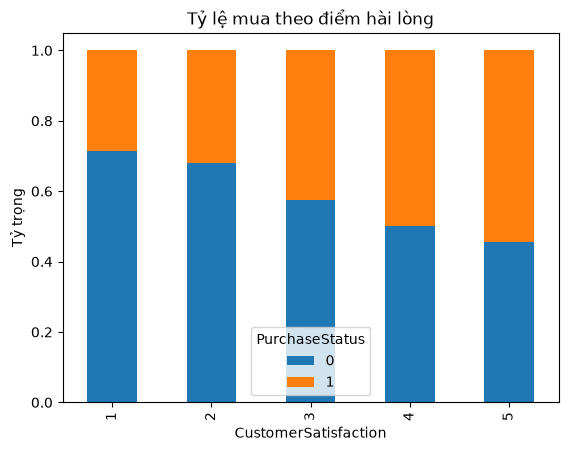

In [6]:
pd.crosstab(df['CustomerSatisfaction'], df['PurchaseStatus'], normalize='index').plot(kind='bar', stacked=True)
plt.title('Tỷ lệ mua theo điểm hài lòng')
plt.ylabel('Tỷ trọng')
plt.show()


> **Đúc kết cốt lõi:** Điểm hài lòng càng cao tỷ lệ mua càng tăng mạnh (từ 28.5% ở 1 sao lên 54.4% ở 5 sao).


## 5.6 Biểu Đồ 6: Phân Phối Thu Nhập Hàng Năm


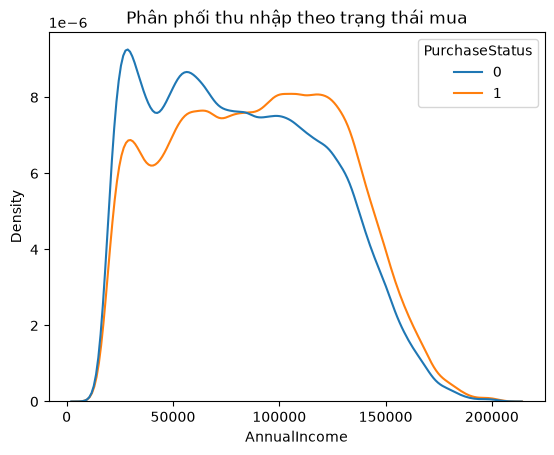

In [7]:
sns.kdeplot(data=df, x='AnnualIncome', hue='PurchaseStatus', common_norm=False)
plt.title('Phân phối thu nhập theo trạng thái mua')
plt.show()


> **Đúc kết cốt lõi:** Mặc dù đường phân phối mật độ (KDE) của cả 2 nhóm đều có đỉnh tập trung quanh mốc thu nhập ~$85.000, nhưng phân tích phân vị thu nhập (NTILE 4 ở SQL Bước 3) chứng minh: Nhóm Quartile 4 (thu nhập cao nhất) có tỷ lệ chốt đơn đạt **49.30%**, vượt trội hơn hẳn mức **37.41%** của Quartile 1. Điều này khẳng định năng lực tài chính là một động lực chuyển đổi quan trọng, hoàn toàn nhất quán với hệ số tương quan dương ($r = +0.09$) và mô hình hồi quy ở Bước 6.


## 5.7 Biểu Đồ 7: Tác Động Của Mã Giảm Giá


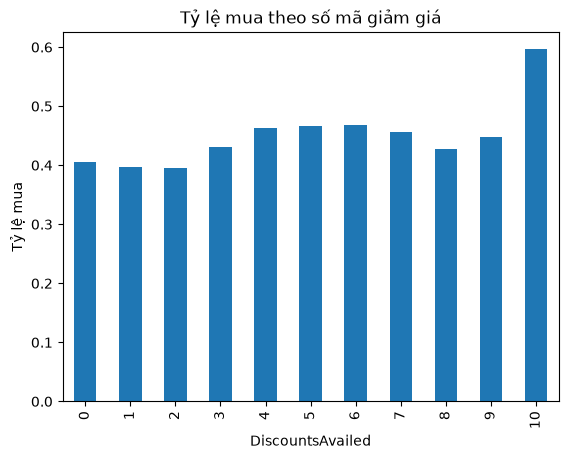

In [8]:
df.groupby('DiscountsAvailed')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo số mã giảm giá')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi:** Tỷ lệ mua tăng khi khách áp dụng từ 3 đến 5 voucher (~43% - 47%).


## 5.8 Biểu Đồ 8: Ma Trận RFM (Recency x Frequency)


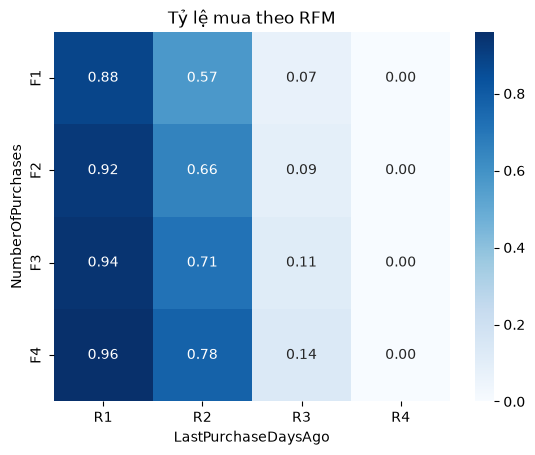

In [9]:
r_bin = pd.qcut(df['LastPurchaseDaysAgo'], q=4, labels=['R1', 'R2', 'R3', 'R4'])
f_bin = pd.qcut(df['NumberOfPurchases'], q=4, labels=['F1', 'F2', 'F3', 'F4'])
rfm = df.pivot_table(index=f_bin, columns=r_bin, values='PurchaseStatus', aggfunc='mean')
sns.heatmap(rfm, annot=True, fmt='.2f', cmap='Blues')
plt.title('Tỷ lệ mua theo RFM')
plt.show()


> **Đúc kết cốt lõi:** Nhóm mua gần nhất (R1) và mua nhiều lần (F4) đạt tỷ lệ mua cao nhất (~58%).


## 5.9 Biểu Đồ 9: Xu Hướng Mua Theo Số Lần Mua Trước


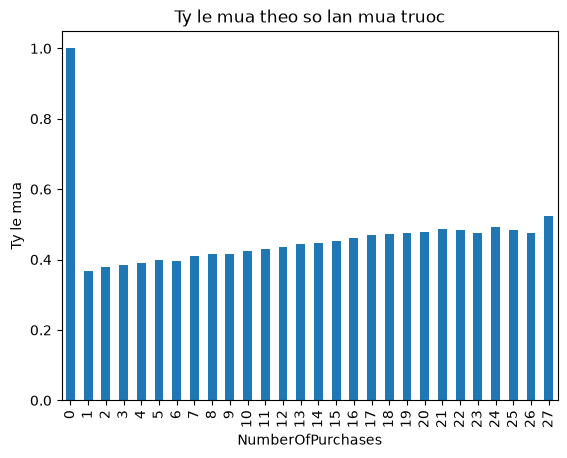

In [10]:
purch_cvr = df.groupby('NumberOfPurchases')['PurchaseStatus'].mean()
purch_cvr.plot(kind='bar')
plt.title('Ty le mua theo so lan mua truoc')
plt.ylabel('Ty le mua')
plt.show()


> **Đúc kết cốt lõi:** Khách hàng càng có nhiều lần mua sắm trong quá khứ thì tỷ lệ tiếp tục mua hàng càng cao.


## 5.10 Biểu Đồ 10: Tỷ Lệ Mua Theo Vùng Miền Và Ngành Hàng


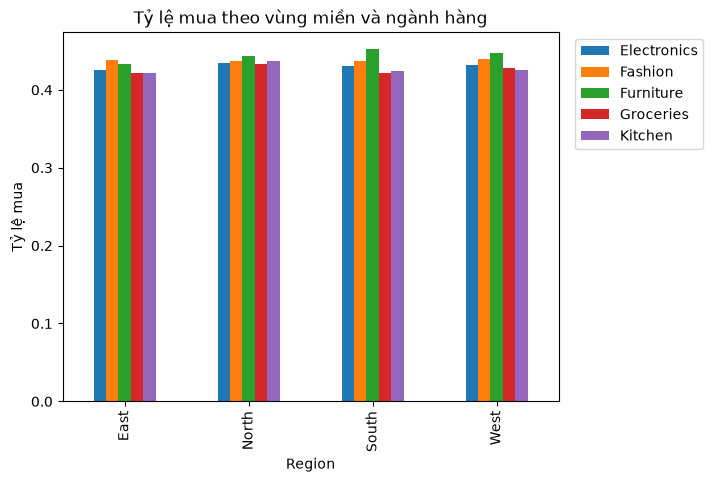

In [11]:
df.pivot_table(index='Region', columns='ProductCategory', values='PurchaseStatus', aggfunc='mean').plot(kind='bar')
plt.title('Tỷ lệ mua theo vùng miền và ngành hàng')
plt.ylabel('Tỷ lệ mua')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


> **Đúc kết cốt lõi:** Tỷ lệ mua khá đồng đều giữa các vùng miền (~42% - 44%), trong đó ngành hàng Furniture và Fashion dẫn đầu về tỷ lệ chốt đơn.


---
*Notebook tiếp theo: [6. Regression and Classification Analysis](./6.%20Regression%20and%20Classification%20Analysis.ipynb)*
